# 06.5 Dynamic topic modeling con BERTopic (Híbrido)

Este cuaderno prepara un flujo para modelar temas dinámicos sobre los posteos de Revista Anfibia usando una arquitectura híbrida:
- **Embeddings/Clustering:** Usa el texto original para capturar la sintaxis y semántica.
- **Representación (Palabras clave):** Usa el texto lematizado para evitar redundancia morfológica en español.

In [1]:
# EJECUTAR ESTA CELDA PRIMERO QUE NADA (Y REINICIAR EL KERNEL ANTES SI FALLÓ)
import coverage.types as ct

# Parche de compatibilidad para evitar que Numba/UMAP crasheen
for name, fallback in {
    'Tracer': getattr(ct, 'TTracer', object),
    'TShouldTraceFn': object,
    'TShouldStartContextFn': object,
    'TFileDisposition': object,
}.items():
    if not hasattr(ct, name):
        setattr(ct, name, fallback)

## 1. Configuración del entorno

In [13]:
import os
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from umap import UMAP
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
from bertopic.representation import KeyBERTInspired
from bertopic import BERTopic

warnings.filterwarnings("ignore", category=UserWarning)

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "corpus_anfibia_lematizado.csv"
STOPWORDS_PATH = PROJECT_ROOT / "data" / "processed" / "stopwords_anfibia.txt"

assert DATA_PATH.exists(), f"Falta archivo de entrada: {DATA_PATH.name}"
assert STOPWORDS_PATH.exists(), f"Falta archivo de stopwords: {STOPWORDS_PATH.name}"

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "bertopic_hibrido"
GRAFICOS_DIR = OUTPUT_DIR / "graficos"
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
GRAFICOS_DIR.mkdir(exist_ok=True, parents=True)

## 2. Carga de Corpus y Stopwords
Preparamos los textos, normalizamos categorías y cargamos la lista de stopwords.

In [14]:
MAX_DOCUMENTS = 4000 ## el corpus igual tiene ~3600
USE_COLUMNS = [
    "doc_id", 
    "ID", "source_url", "title_text", "tagline", "autor_names",
    "post_date", "category", "post_tag", "text_type",
    "document_text_original", "document_text_final"
]

df = pd.read_csv(DATA_PATH, usecols=USE_COLUMNS, nrows=MAX_DOCUMENTS)

print(f"Documentos listos: {df.shape[0]}")

# Normalizar categorías vectorizado
def split_categories(val):
    return [p.strip() for p in re.split(r"[;,]", str(val)) if p.strip()]

categories_df = (
    df[["doc_id", "category"]]
    .assign(category_normalized=df["category"].map(split_categories))
    .explode("category_normalized")
    .fillna({"category_normalized": "Sin categoria"})
    [["doc_id", "category_normalized"]]
)

# Textos, fechas y stopwords
docs_naturales = df["document_text_original"].tolist()
docs_lematizados = df["document_text_final"].tolist()
timestamps = pd.to_datetime(df["post_date"].str.split(' ').str[0], format="%Y-%m-%d", errors="coerce")

with open(STOPWORDS_PATH, "r", encoding="utf-8") as f:
    STOPWORDS_LIST = f.read().splitlines()

Documentos listos: 3556


## 3. Entrenamiento Híbrido y Reducción de Outliers (Instancia Única)

1. Calculamos embeddings sobre el texto.
2. Clusterizamos (UMAP + HDBSCAN).
3. Reasignamos las notas outliers (-1).
4. Extraemos las palabras clave con el texto lematizado y las stopwords.

In [15]:
from hdbscan import HDBSCAN

print("1. Calculando embeddings originales...")
embedding_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
embeddings_naturales = embedding_model.encode(docs_naturales, show_progress_bar=True)

print("\n2. Configurando componentes...")
vectorizer_model = CountVectorizer(stop_words=STOPWORDS_LIST, min_df=3)
representation_model = KeyBERTInspired()
umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine', random_state=42)

#
hdbscan_model = HDBSCAN(
    min_cluster_size=10,       
    min_samples=3,            
    metric='euclidean',
    cluster_selection_method='eom',
    prediction_data=True
)

print("\n3. Entrenando modelo base...")
topic_model = BERTopic(
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,      
    embedding_model=embedding_model,
    language="spanish",
    calculate_probabilities=True,
    # min_topic_size ya no hace falta porque lo maneja hdbscan_model
    nr_topics=None,
    representation_model=representation_model,
    vectorizer_model=vectorizer_model,
)

topics_base, probs = topic_model.fit_transform(docs_lematizados, embeddings=embeddings_naturales)


######################### 

# print("\n3. Reasignando notas outliers (-1)...")
# topics_reducidos = topic_model.reduce_outliers(
#     docs_lematizados,
#     topics_base,
#     strategy="embeddings",
#     embeddings=embeddings_naturales
# )

# print("\n4. Recalibrando palabras clave lematizadas de los tópicos (c-TF-IDF)...")
# # Hay que pasarle el vectorizador de nuevo sí o sí
# topic_model.update_topics(
#     docs_lematizados, 
#     topics=topics_reducidos,
#     vectorizer_model=vectorizer_model,
#     representation_model=representation_model
# )
#topics = topics_reducidos

topic_model.save(OUTPUT_DIR / "bertopic_hibrido_model") 

print("\nModelo optimizado y guardado exitosamente.")

1. Calculando embeddings originales...


Batches: 100%|██████████| 112/112 [01:33<00:00,  1.20it/s]



2. Configurando componentes...

3. Entrenando modelo base...


2026-10-09 09:25:45,891 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.



Modelo optimizado y guardado exitosamente.


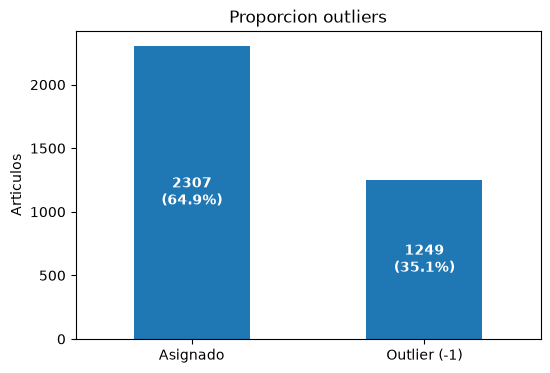

In [17]:
topicos = topics_base

import pandas as pd

counts = pd.Series(["Outlier (-1)" if t == -1 else "Asignado" for t in topicos]).value_counts()

ax = counts.plot(kind="bar", rot=0,figsize=(6, 4))
plt.title("Proporcion outliers")
plt.ylabel("Articulos")

for i, val in enumerate(counts):
    ax.text(i, val / 2, f"{val}\n({val/len(topicos):.1%})", ha="center", va="center", color="white", fontweight="bold")
plt.show()

In [22]:
# Ver tipo, longitud total y los primeros 15 elementos
print(type(topicos))
print(f"Total documentos: {len(topicos)}")

# Ver conteo de documentos por tópico (incluyendo el -1)
import pandas as pd
conteo = pd.Series(topicos).value_counts().sort_index()
print(conteo)

<class 'list'>
Total documentos: 3556
-1     1249
 0      140
 1      134
 2      119
 3      115
       ... 
 75      10
 76      10
 77      10
 78      10
 79      10
Name: count, Length: 81, dtype: int64


In [25]:
import math
import plotly.express as px

def topicos_palabras(topic_model, df, topicos, ruta_html=None):
    df['topic'] = topicos
    total = len(topic_model.get_topic_info().query("Topic != -1"))
    
    fig = topic_model.visualize_barchart(
        top_n_topics=total, 
        n_words=8, 
        title="<b>Palabras representativas (Híbrido)</b>"
    )
    
    colors = px.colors.qualitative.G10
    for i, trace in enumerate(fig.data):
        trace.marker.color = colors[i % len(colors)]
        
    fig.update_traces(hovertemplate="<b>Término:</b> %{y}<br><b>Relevancia:</b> %{x:.3f}<extra></extra>")
    fig.for_each_xaxis(lambda ax: ax.update(title_text="", showticklabels=False))
    fig.for_each_annotation(lambda a: a.update(text=f"<b>{a.text.split('_')[0]}</b>"))
    
    altura = max(950, math.ceil(total / 4) * 300)
    fig.update_layout(height=altura, width=1300, plot_bgcolor='rgba(0,0,0,0)', paper_bgcolor='#ffffff')
    
    if ruta_html:
        fig.write_html(ruta_html)
        
    fig.show()

In [26]:
topicos_palabras(topic_model,df,topicos)

In [27]:
hierarchical_topics = topic_model.hierarchical_topics(docs_lematizados)

100%|██████████| 79/79 [00:39<00:00,  2.01it/s]


In [28]:
fig_tree = topic_model.visualize_hierarchy(hierarchical_topics=hierarchical_topics)
fig_tree.show()
fig_tree.write_html("arbol_0.html")

In [29]:
tree = topic_model.get_topic_tree(hierarchical_topics)
print(tree)

.
├─candidato_oposición_presidencial_campaña_democracia
│    ├─endeudamiento_economista_deuda_déficit_fiscal
│    │    ├─deuda_endeudamiento_inflacionario_monetario_fiscal
│    │    │    ├─■──alfonso_alfonsín_lopetegui_jefatura_dujovne ── Topic: 64
│    │    │    └─monetario_deuda_inflacionario_endeudamiento_inflación
│    │    │         ├─■──sociedad_ganancia_milei_bono_internacional ── Topic: 10
│    │    │         └─■──sociedad_cápita_mundo_social_galperín ── Topic: 16
│    │    └─sindicalismo_sindicalista_reforma_sindical_sindicato
│    │         ├─■──aporte_previsional_país_precario_mundo ── Topic: 51
│    │         └─■──sergio_cegetista_obra_gremio_azopardo ── Topic: 24
│    └─oposición_candidato_electoral_libertario_democrático
│         ├─judicial_justicia_juzgado_tribunal_juez
│         │    ├─judicial_justicia_juzgado_tribunal_juez
│         │    │    ├─jurisprudencia_judicial_tribunal_justicia_juez
│         │    │    │    ├─■──alessio_villarruel_periodista_cristina_fernánde

In [58]:
import plotly.graph_objects as go

# 1. Sacar info de los tópicos base, volando el -1 (outliers) que rompe la jerarquía
info = topic_model.get_topic_info()
info = info[info['Topic'] != -1]
dic_tamaños = dict(zip(info['Topic'], info['Count']))

# 2. Mapear quién es hijo de quién usando el dataframe de uniones
padre_de = {}
for _, row in hierarchical_topics.iterrows():
    # Convertimos a int y string para evitar que Plotly lea "15.0" y rompa las relaciones
    padre_de[int(row['Child_Left_ID'])] = str(int(row['Parent_ID']))
    padre_de[int(row['Child_Right_ID'])] = str(int(row['Parent_ID']))

# Listas que alimentan el gráfico
ids, labels, parents, values = [], [], [], []

# 3. Cargar las "hojas" del árbol (tus tópicos base originales)
for _, row in info.iterrows():
    t_id = int(row['Topic'])
    ids.append(str(t_id))
    labels.append(row['Name'])
    parents.append(padre_de.get(t_id, "")) # Si no tiene padre, va a la raíz ("")
    values.append(row['Count'])

# 4. Cargar las "ramas" (las agrupaciones que hizo BERTopic)
for _, row in hierarchical_topics.iterrows():
    p_id = int(row['Parent_ID'])
    ids.append(str(p_id))
    labels.append(row['Parent_Name'])
    parents.append(padre_de.get(p_id, ""))
    
    # El tamaño del padre es la sumatoria exacta de todos los tópicos base que arrastra
    suma_filas = sum(dic_tamaños.get(t, 0) for t in row['Topics'])
    values.append(suma_filas)

fig = go.Figure(go.Treemap(
    ids=ids,
    labels=labels,
    parents=parents,
    values=values,
    branchvalues="total", 
    # texttemplate pisa al textinfo y te deja armarlo a medida
    texttemplate=(
        "<b>%{label}</b><br>"
        "%{value} filas<br>"
        "%{percentRoot:.1%} del total<br>"
        "%{percentParent:.1%} del grupo"
    ),
    # Mejoramos también el cuadro negro al pasar el mouse
    hovertemplate=(
        "<b>%{label}</b><br>"
        "Filas: %{value}<br>"
        "Del total general: %{percentRoot:.2%}<br>"
        "De su unión superior: %{percentParent:.2%}"
        "<extra></extra>"
    )
))

fig.update_layout(
    title="Jerarquía de Tópicos (Treemap con ambos porcentajes)",
    margin=dict(t=50, l=25, r=25, b=25)
)

fig.show()
fig.write_html("treemap_topicos.html")

In [59]:
# 1. Armamos un diccionario con todos los nodos para buscar rápido
nodos = {id_: {'label': label, 'parent': parent, 'value': value} 
         for id_, label, parent, value in zip(ids, labels, parents, values)}

# 2. Buscamos el nodo raíz (el que engloba todo y no tiene padre)
raices = [id_ for id_, data in nodos.items() if data['parent'] == ""]
total_filas = sum(nodos[r]['value'] for r in raices)

# 3. Función recursiva para imprimir el árbol
def imprimir_arbol(node_id, nivel=0):
    nodo = nodos[node_id]
    value = nodo['value']
    parent_id = nodo['parent']
    
    # Cálculos
    pct_total = (value / total_filas) * 100 if total_filas > 0 else 0
    pct_parent = (value / nodos[parent_id]['value']) * 100 if parent_id != "" else 100.0
    
    # Formato visual en la consola
    sangria = "    " * nivel
    rama = "↳ " if nivel > 0 else "■ "
    
    # Imprimimos la línea
    print(f"{sangria}{rama}{nodo['label']} | Filas: {value} | {pct_total:.1f}% del total | {pct_parent:.1f}% de su grupo")
    
    # Buscamos quiénes son hijos de este nodo y los ordenamos de mayor a menor (por filas)
    hijos = [id_ for id_, d in nodos.items() if d['parent'] == node_id]
    hijos.sort(key=lambda x: nodos[x]['value'], reverse=True)
    
    # Llamamos a la misma función para cada hijo
    for h in hijos:
        imprimir_arbol(h, nivel + 1)

print("\n--- ESTRUCTURA DE TÓPICOS ---")
for r in raices:
    imprimir_arbol(r)


--- ESTRUCTURA DE TÓPICOS ---
■ democracia_campaña_gobierno_debate_presidente | Filas: 3556 | 100.0% del total | 100.0% de su grupo
    ↳ feminista_feminismo_escritor_periodista_aborto | Filas: 1913 | 53.8% del total | 53.8% de su grupo
        ↳ feminismo_feminista_aborto_debate_libertad | Filas: 1090 | 30.7% del total | 57.0% de su grupo
            ↳ feminismo_feminista_aborto_libertad_violencia | Filas: 967 | 27.2% del total | 88.7% de su grupo
                ↳ aborto_feminismo_feminista_debate_libertad | Filas: 909 | 25.6% del total | 94.0% de su grupo
                    ↳ violencia_delito_víctima_crimen_cárcel | Filas: 522 | 14.7% del total | 57.4% de su grupo
                        ↳ violencia_víctima_matar_crimen_detenido | Filas: 465 | 13.1% del total | 89.1% de su grupo
                            ↳ comisaría_dictadura_militante_asesinato_desaparición | Filas: 333 | 9.4% del total | 71.6% de su grupo
                                ↳ comisaría_asesinato_santiago_desaparic

In [60]:
import pandas as pd

# 1. Analizar Frecuencia en el Corpus (Document Frequency)
vectorizador = topic_model.vectorizer_model
matriz_conteo = vectorizador.transform(docs_lematizados)
vocabulario = vectorizador.get_feature_names_out()

# Calculamos en cuántos documentos aparece cada palabra
doc_freq = (matriz_conteo > 0).sum(axis=0).A1
df_frecuencias = pd.DataFrame({'Palabra': vocabulario, 'Apariciones_Docs': doc_freq})
df_frecuencias['Porcentaje_Corpus'] = (df_frecuencias['Apariciones_Docs'] / len(docs_lematizados)) * 100

# 2. Analizar Redundancia en los Tópicos (c-TF-IDF)
# Revisamos en cuántos tópicos la palabra logró meterse en el Top 10
palabras_top = []
for topic_id in topic_model.get_topic_info()['Topic']:
    if topic_id == -1: continue
    # get_topic trae las palabras más representativas y su score
    for word, score in topic_model.get_topic(topic_id):
        palabras_top.append({'Topic_ID': topic_id, 'Palabra': word, 'c-TF-IDF': score})

df_topicos = pd.DataFrame(palabras_top)

# 3. Filtramos los lemas que queremos auditar
# (Poné las versiones con y sin tilde por las dudas de cómo haya quedado tu lematización)
lemas_a_auditar = ["político", "política", "politico", "politica", "país", "pais", "gobierno"]

print("--- 1. PRESENCIA EN EL CORPUS (Document Frequency) ---")
print(df_frecuencias[df_frecuencias['Palabra'].isin(lemas_a_auditar)].sort_values('Porcentaje_Corpus', ascending=False).to_string(index=False))

print("\n--- 2. REDUNDANCIA EN TÓPICOS ---")
for lema in lemas_a_auditar:
    apariciones = df_topicos[df_topicos['Palabra'] == lema]
    if not apariciones.empty:
        cantidad_topicos = len(apariciones)
        score_promedio = apariciones['c-TF-IDF'].mean()
        print(f"El lema '{lema}' aparece como palabra clave en {cantidad_topicos} tópicos distintos (Score prom: {score_promedio:.3f})")

--- 1. PRESENCIA EN EL CORPUS (Document Frequency) ---
 Palabra  Apariciones_Docs  Porcentaje_Corpus
    país              2414          67.885264
gobierno              1859          52.277840
    pais                 6           0.168729

--- 2. REDUNDANCIA EN TÓPICOS ---
El lema 'país' aparece como palabra clave en 1 tópicos distintos (Score prom: 0.407)
El lema 'gobierno' aparece como palabra clave en 3 tópicos distintos (Score prom: 0.437)


In [61]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

# 1. Usamos un vectorizador temporal ignorando tus stopwords actuales 
# para ver qué es lo que más sobrevive en el texto limpio.
vectorizador_exploratorio = CountVectorizer(stop_words=STOPWORDS_LIST)
X = vectorizador_exploratorio.fit_transform(docs_lematizados)

# 2. Calculamos en cuántos documentos (notas) aparece cada palabra
doc_freq = (X > 0).sum(axis=0).A1
vocabulario = vectorizador_exploratorio.get_feature_names_out()

# 3. Armamos el DataFrame
df_ruido = pd.DataFrame({
    'Lema': vocabulario,
    'Apariciones_Docs': doc_freq
})

# Calculamos el porcentaje: (Docs donde aparece / Total de docs) * 100
total_docs = len(docs_lematizados)
df_ruido['Porcentaje_Corpus'] = (df_ruido['Apariciones_Docs'] / total_docs) * 100

# 4. Ordenamos de mayor a menor y filtramos el top
# Un umbral clásico es mirar todo lo que supere el 15% o 20%
umbral_alarma = 15.0 
candidatas_stopwords = df_ruido[df_ruido['Porcentaje_Corpus'] >= umbral_alarma].sort_values('Porcentaje_Corpus', ascending=False)

print(f"--- POSIBLES STOPWORDS DE DOMINIO (Aparecen en más del {umbral_alarma}% de Anfibia) ---")
print(candidatas_stopwords.head(30).to_string(index=False))

--- POSIBLES STOPWORDS DE DOMINIO (Aparecen en más del 15.0% de Anfibia) ---
      Lema  Apariciones_Docs  Porcentaje_Corpus
    social              2536          71.316085
     mundo              2477          69.656918
      país              2414          67.885264
   público              2383          67.013498
   trabajo              2182          61.361080
      casa              2009          56.496063
  nacional              1978          55.624297
    cambio              1940          54.555681
     mujer              1884          52.980877
  gobierno              1859          52.277840
  sociedad              1701          47.834646
    ciudad              1693          47.609674
   derecho              1654          46.512936
    fuerza              1652          46.456693
    hombre              1632          45.894263
   familia              1628          45.781777
    cuerpo              1613          45.359955
       red              1596          44.881890
 económico 

In [62]:
import pandas as pd
from collections import defaultdict

# 1. Sacamos todos los tópicos válidos (excluyendo el ruido -1)
topic_info = topic_model.get_topic_info()
topicos_validos = topic_info[topic_info['Topic'] != -1]
total_topicos = len(topicos_validos)

# 2. Diccionario para acumular los scores: { "palabra": [score1, score2, ...] }
apariciones_palabras = defaultdict(list)

# 3. Barremos todos los tópicos y anotamos qué palabras eligió el modelo
for t_id in topicos_validos['Topic']:
    palabras_topico = topic_model.get_topic(t_id)
    for word, score in palabras_topico:
        apariciones_palabras[word].append(score)

# 4. Procesamos los datos
data_redundancia = []
for word, scores in apariciones_palabras.items():
    apariciones = len(scores)
    
    # Filtro: Solo nos importan las palabras que "contaminan" más de 1 tópico
    if apariciones > 1:
        data_redundancia.append({
            "Palabra": word,
            "Aparece_en_N_Topicos": apariciones,
            "%_de_Topicos_Contaminados": round((apariciones / total_topicos) * 100, 1),
            "Score_c-TF-IDF_Promedio": round(sum(scores) / len(scores), 3)
        })

# 5. Armamos el DataFrame y lo ordenamos de mayor a menor redundancia
df_prueba = pd.DataFrame(data_redundancia).sort_values("Aparece_en_N_Topicos", ascending=False)

print(f"Total de tópicos válidos en el modelo: {total_topicos}\n")
print("--- PALABRAS MÁS REDUNDANTES DEL MODELO ---")
# Imprimimos el top 30 o todas si son menos
print(df_prueba.head(30).to_string(index=False))

Total de tópicos válidos en el modelo: 43

--- PALABRAS MÁS REDUNDANTES DEL MODELO ---
     Palabra  Aparece_en_N_Topicos  %_de_Topicos_Contaminados  Score_c-TF-IDF_Promedio
   electoral                     4                        9.3                    0.528
   candidato                     4                        9.3                    0.527
    sociedad                     4                        9.3                    0.437
     campaña                     3                        7.0                    0.520
   feminista                     3                        7.0                    0.613
      debate                     3                        7.0                    0.477
      muerto                     3                        7.0                    0.481
     víctima                     3                        7.0                    0.471
      pueblo                     3                        7.0                    0.453
    gobierno                     3         

In [64]:
# Fusión final basada en el árbol limpio (sin ruido transversal)
grupos_a_fusionar = [
    # 1. Literatura, Cine y Arte
    [3, 34],   # [literario_escritora_autor] + [película_personaje_actor]
    [24, 26],  # [arte_artes_estética] + [fotoperiodismo_retratar]
    
    # 2. Música y Espectáculo
    [22, 38],  # [música_musical_rapero] + [bailarín_tango_ballet]
    
    # 3. Género y Violencia Patriarcal
    [1, 25],   # [feminismo_patriarcado_masculinidad] + [violencia_feminismo_violación]
    
    # 4. Policiales y Derechos Humanos
    [6, 11],   # [asesinato_policía_maldonado] + [asesino_testimonio_víctima]
    
    # 5. Geopolítica y Conflictos Internacionales
    [27, 36],  # [israel_palestina] + [holocausto_terrorista_siria]
    
    # 6. Economía, Deuda y Pobreza
    [4, 41],   # [déficit_deuda_inflación] + [pobreza_inmobiliario_vecino]
    
    # 7. Sociedad, Crisis y Futuro
    [28, 30],  # [futuro_crisis_pandemia] + [sociedad_comunitario_proyecto]
    
    # 8. Política Electoral Sudamericana
    [0, 10],   # [electoral_candidato_argentina] + [boliviano_bolivia_electoral]
    
    # 9. Catástrofes Naturales
    [20, 32],  # [ríos_río_inundación] + [catástrofe_desastre_terremoto]
    
    # 10. Medios y Tecnología
    [14, 31]   # [mediático_periodístico_noticia] + [digital_internet_tecnología]
]

# 1. Aplicamos la fusión al modelo usando los textos lematizados
topic_model.merge_topics(docs_lematizados, grupos_a_fusionar)

# 2. Recalculamos la jerarquía final con los IDs consolidados
hierarchical_topics_final = topic_model.hierarchical_topics(docs_lematizados)

# 3. Chequeo de cómo quedaron los nombres definitivos
info_final = topic_model.get_topic_info()
print(info_final[['Topic', 'Count', 'Name']].head(15))

# 4. Generás tu gráfico final para el TP
fig_tree_final = topic_model.visualize_hierarchy(hierarchical_topics=hierarchical_topics_final)
fig_tree_final.write_html(GRAFICOS_DIR / "01_arbol_jerarquico_definitivo.html")
fig_tree_final.show()

100%|██████████| 31/31 [00:21<00:00,  1.47it/s]

    Topic  Count                                            Name
0       0    556            0_electoral_candidato_debate_campaña
1       1    308            1_literario_poeta_escritora_escritor
2       2    296              2_asesinato_comisaría_matar_pueblo
3       3    296  3_feminismo_feminista_masculinidad_patriarcado
4       4    217           4_inflación_monetario_fiscal_economía
5       5    153                5_fifa_futbolista_fútbol_deporte
6       6    148                 6_agenda_futuro_crisis_sociedad
7       7    132        7_pedagógico_enseñanza_escolar_educativo
8       8    130     8_mediático_periodístico_periodista_noticia
9       9    112                 9_música_musical_músico_canción
10     10     91       10_aborto_abortar_anticonceptivo_embarazo
11     11     88                       11_arte_art_artes_artista
12     12     86                12_epidemia_vacunar_virus_vacuna
13     13     84          13_economía_económico_futuro_ambiental
14     14     78         

In [65]:
tree = topic_model.get_topic_tree(hierarchical_topics_final)
print(tree)

.
├─feminismo_feminista_literatura_aborto_mujer
│    ├─■──padre_papá_hijo_abuelo_hermano ── Topic: 29
│    └─feminismo_feminista_literatura_violencia_periodista
│         ├─periodista_autor_publicar_escritor_literatura
│         │    ├─periodista_publicar_violencia_literatura_escritor
│         │    │    ├─■──fifa_futbolista_fútbol_deporte_brasil ── Topic: 5
│         │    │    └─autor_publicar_escritor_periodista_literario
│         │    │         ├─■──periodista_periodístico_periódico_narrativo_escritora ── Topic: 18
│         │    │         └─muerto_muerte_víctima_morir_publicar
│         │    │              ├─publicar_autor_carlos_muerto_periodista
│         │    │              │    ├─■──pedagógico_enseñanza_escolar_educativo_enseñar ── Topic: 7
│         │    │              │    └─autor_literario_escritor_periodista_publicar
│         │    │              │         ├─publicar_periodista_autor_escritor_ficción
│         │    │              │         │    ├─■──manifestación_feminista

In [66]:
# Grupos súper específicos basados en las uniones más fuertes del nuevo árbol
grupos_a_fusionar = [
    # 1. Política Electoral y Nueva Derecha
    [0, 16],   # [electoral_candidato_debate] + [libertario_presidencial_liberal]
    
    # 2. Feminismo y Derechos Reproductivos
    [3, 10],   # [feminismo_patriarcado_masculinidad] + [aborto_anticonceptivo_embarazo]
    
    # 3. Arte, Música y Ficción
    [9, 11, 15], # [música_canción] + [arte_artista_estética] + [ficción_personaje_película]
    
    # 4. Salud Pública y Pandemia
    [12, 24],  # [epidemia_virus_vacuna] + [morir_muerte_fallecido]
    
    # 5. Economía y Contexto Social
    [4, 6],    # [inflación_monetario_deuda] + [agenda_futuro_crisis]
    
    # 6. Medios y Ecosistema Digital
    [8, 21],   # [mediático_periodístico_noticia] + [innovación_tecnología_inteligencia]
    
    # 7. Geopolítica y Conflictos Bélicos
    [22, 28],  # [israel_palestina] + [soviética_rusia_ucrania]
    
    # 8. Literatura y Periodismo Narrativo (Armado a mano porque el árbol los separó por un ruido de T2)
    [1, 18]    # [literario_poeta_libro] + [periodista_narrativo_escritora]
]

# 1. Aplicamos la fusión definitiva usando los textos lematizados
topic_model.merge_topics(docs_lematizados, grupos_a_fusionar)

# 2. Recalculamos la jerarquía final
hierarchical_topics_final = topic_model.hierarchical_topics(docs_lematizados)

# 3. Chequeo de la tabla de tópicos consolidados
info_final = topic_model.get_topic_info()
print(f"Total de tópicos tras la fusión: {len(info_final[info_final['Topic'] != -1])}")
print(info_final[['Topic', 'Count', 'Name']].head(15))

# 4. Exportamos el árbol definitivo
fig_tree_final = topic_model.visualize_hierarchy(hierarchical_topics=hierarchical_topics_final)
fig_tree_final.write_html(GRAFICOS_DIR / "01_arbol_jerarquico_definitivo.html")
fig_tree_final.show()

# 5. Guardamos el modelo pisando el anterior
topic_model.save(OUTPUT_DIR / "bertopic_hibrido_model")

100%|██████████| 22/22 [00:17<00:00,  1.28it/s]

Total de tópicos tras la fusión: 23
    Topic  Count                                       Name
0       0    625     0_candidato_electoral_campaña_discurso
1       1    387   1_feminismo_feminista_aborto_patriarcado
2       2    371  2_periodista_literario_escritora_escritor
3       3    365          3_deuda_economía_crisis_económico
4       4    296     4_comisaría_asesinato_violencia_delito
5       5    274      5_artista_artístico_arte_protagonista
6       6    186       6_mediático_noticia_sociedad_público
7       7    153           7_fifa_futbolista_fútbol_deporte
8       8    132   8_pedagógico_enseñanza_escolar_educativo
9       9    125      9_epidemia_coronavirus_pandemia_virus
10     10     84     10_economía_económico_futuro_ambiental
11     11     78              11_soviético_rusia_moscú_ruso
12     12     78                12_arroyo_río_paisaje_monte
13     13     67    13_sindicalismo_reforma_laboral_trabajo
14     14     58    14_papal_catolicismo_arzobispo_católica


2026-10-03 10:53:25,460 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.


In [67]:
tree = topic_model.get_topic_tree(hierarchical_topics)
print(tree)

.
├─feminista_feminismo_escritor_periodista_aborto
│    ├─periodista_escritor_literario_autor_ficción
│    │    ├─■──padre_papá_hijo_abuelo_hermano ── Topic: 42
│    │    └─literario_periodista_autor_escritor_literatura
│    │         ├─periodista_escritor_literario_autor_protagonista
│    │         │    ├─■──fifa_futbolista_fútbol_deporte_brasil ── Topic: 2
│    │         │    └─literario_poeta_escritor_autor_literatura
│    │         │         ├─■──periodista_periodístico_periódico_narrativo_escritora ── Topic: 19
│    │         │         └─poeta_literario_autor_escritor_poesía
│    │         │              ├─literario_poeta_escritora_libro_escritor
│    │         │              │    ├─■──ficción_protagonista_personaje_melodrama_película ── Topic: 29
│    │         │              │    └─literario_escritora_autor_literatura_escritor
│    │         │              │         ├─■──película_personaje_actor_hombre_américo ── Topic: 34
│    │         │              │         └─■──literario_e

In [68]:
# 1. Asignar al df original 
df['topic'] = topics

# 2. Obtenemos la cantidad total de tópicos válidos (excluyendo el -1)
total_topicos = len(topic_model.get_topic_info()[topic_model.get_topic_info()['Topic'] != -1])

# 3. Le pasamos el total exacto a la función
fig = topic_model.visualize_barchart(
    top_n_topics=total_topicos, 
    n_words=8, 
    title="<b>Palabras representativas (Híbrido)</b>"
)

colors = px.colors.qualitative.G10
for i, trace in enumerate(fig.data):
    trace.marker.color = colors[i % len(colors)]

fig.update_traces(hovertemplate="<b>Término:</b> %{y}<br><b>Relevancia:</b> %{x:.3f}<extra></extra>")
fig.for_each_xaxis(lambda ax: ax.update(title_text="", showticklabels=False))
fig.for_each_annotation(lambda a: a.update(text=f"<b>{a.text.split('_')[0]}</b>"))

# 4. Altura dinámica: le damos aprox 300px por cada fila de 4 gráficos para que no se aplasten
altura_dinamica = max(950, (total_topicos // 4) * 300)

fig.update_layout(
    height=altura_dinamica, 
    width=1300, 
    plot_bgcolor='rgba(0,0,0,0)', 
    paper_bgcolor='#ffffff'
)

fig.write_html(GRAFICOS_DIR / "01_barchart_topicos.html")
fig.show()

In [70]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

# 1. Reutilizamos el vectorizador entrenado por BERTopic
vectorizer = topic_model.vectorizer_model
X = vectorizer.transform(docs_lematizados)
binary_matrix = (X > 0).astype(int)

doc_counts = np.array(binary_matrix.sum(axis=0)).flatten()
n_docs = binary_matrix.shape[0]

# 2. Función para calcular el NPMI del Top 10 de cada tópico
def calculate_topic_npmi(words, top_n=10):
    words = words[:top_n]
    vocab = vectorizer.vocabulary_
    indices = [vocab[w] for w in words if w in vocab]
    
    if len(indices) < 2: 
        return 0.0
    
    npmi_scores = []
    for i in range(len(indices)):
        for j in range(i + 1, len(indices)):
            idx_i, idx_j = indices[i], indices[j]
            p_i = doc_counts[idx_i] / n_docs
            p_j = doc_counts[idx_j] / n_docs
            
            # Coocurrencia directa sobre la matriz booleana
            cooc = binary_matrix[:, idx_i].T.dot(binary_matrix[:, idx_j])[0, 0]
            p_ij = cooc / n_docs
            
            if p_ij > 0:
                npmi_scores.append((np.log2(p_ij / (p_i * p_j))) / (-np.log2(p_ij)))
            else:
                npmi_scores.append(-1.0)
                
    return np.mean(npmi_scores) if npmi_scores else 0.0

# 3. Consolidamos métricas por cada tópico válido (fuera del -1)
counts_dict = topic_model.get_topic_info().set_index("Topic")["Count"].to_dict()

topic_metrics = []
for t_id, words_weights in topic_model.get_topics().items():
    if t_id == -1: 
        continue
    words = [w for w, _ in words_weights]
    count = counts_dict.get(t_id, 0)
    
    # Clasificación diagnóstica automática
    npmi_val = calculate_topic_npmi(words)
    if npmi_val >= 0.10:
        diag = "Alta coherencia"
    elif npmi_val >= 0.00:
        diag = "Aceptable / Amplio"
    else:
        diag = "Ruidoso"

    topic_metrics.append({
        "Topic": t_id,
        "Name": ", ".join(words[:4]),
        "Docs": count,
        "% Corpus": round((count / n_docs) * 100, 2),
        "Coherencia_NPMI": round(npmi_val, 4),
        "Diagnóstico": diag
    })

metrics_df = pd.DataFrame(topic_metrics).sort_values(by="Docs", ascending=False)

print(f"--- AUDITORÍA DE COHERENCIA NPMI ({len(metrics_df)} Tópicos) ---")
display(metrics_df)

--- AUDITORÍA DE COHERENCIA NPMI (23 Tópicos) ---


,Topic,Name,Docs,% Corpus,Coherencia_NPMI,Diagnóstico
0,0,"candidato, electoral, campaña, discurso",625,17.58,0.2791,Alta coherencia
1,1,"feminismo, feminista, aborto, patriarcado",387,10.88,0.2468,Alta coherencia
2,2,"periodista, literario, escritora, escritor",371,10.43,0.2117,Alta coherencia
3,3,"deuda, economía, crisis, económico",365,10.26,0.2155,Alta coherencia
4,4,"comisaría, asesinato, violencia, delito",296,8.32,0.2200,Alta coherencia
5,5,"artista, artístico, arte, protagonista",274,7.71,0.1273,Alta coherencia
6,6,"mediático, noticia, sociedad, público",186,5.23,0.0850,Aceptable / Amplio
7,7,"fifa, futbolista, fútbol, deporte",153,4.30,0.3627,Alta coherencia
8,8,"pedagógico, enseñanza, escolar, educativo",132,3.71,0.2686,Alta coherencia
9,9,"epidemia, coronavirus, pandemia, virus",125,3.52,0.3887,Alta coherencia


In [75]:
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# 1. Sincronizamos los tópicos reales del modelo (post-fusión) con el DataFrame
topics, _ = topic_model.transform(docs_lematizados)
df['topic'] = topics

# 2. Obtenemos la lista limpia de IDs válidos actualizados
top_topics_ids = [t for t in topic_model.get_topic_info()["Topic"].tolist() if t != -1]

# ==============================================================================
# 1. CÁLCULO AUTOMÁTICO DE TOPICS OVER TIME
# ==============================================================================
print("Calculando evolución temporal y picos para las trazas limpias...")

# Aseguramos formato de fechas en el df
df["post_date_dt"] = pd.to_datetime(df["post_date"], errors="coerce")
timestamps_lista = df["post_date_dt"].dt.to_pydatetime().tolist()
docs_lem_lista = df["document_text_final"].fillna("").astype(str).tolist()

# Generamos la tabla temporal desde BERTopic
topics_over_time = topic_model.topics_over_time(
    docs=docs_lem_lista,
    timestamps=timestamps_lista,
    global_tuning=True,
    evolution_tuning=True,
    nr_bins=25
)

# Diccionario de nombres limpios para los tópicos
topic_names_dict = {}
for t_id in top_topics_ids:
    words_weights = topic_model.get_topic(t_id)
    if words_weights:
        topic_names_dict[t_id] = f"{t_id}_" + "_".join([w for w, _ in words_weights[:3]])
    else:
        topic_names_dict[t_id] = f"Topic_{t_id}"

# ==============================================================================
# 2. DETECCIÓN DE PICOS Y EXTRACCIÓN DE ARTÍCULOS REPRESENTATIVOS
# ==============================================================================
TOP_N_NOTAS_PICO = 3
TOP_N_NOTAS_NORMAL = 1
MIN_FREQ_PICO = 3

unique_timestamps = sorted(pd.to_datetime(topics_over_time["Timestamp"].unique()))
timeline_data = []

for t_id in top_topics_ids:
    df_t = topics_over_time[topics_over_time["Topic"] == t_id].sort_values("Timestamp").reset_index(drop=True)
    if df_t.empty:
        continue
    
    t_name = topic_names_dict.get(t_id, f"Topic_{t_id}")
    freqs = df_t["Frequency"].values
    
    umbral = max(MIN_FREQ_PICO, freqs.mean())
    if len(freqs) > 2:
        mayor_al_anterior = np.r_[False, freqs[1:] > freqs[:-1]]
        mayor_al_siguiente = np.r_[freqs[:-1] > freqs[1:], False]
        picos_locales = mayor_al_anterior & mayor_al_siguiente & (freqs >= umbral)
        picos_idx = set(np.where(picos_locales)[0])
    else:
        picos_idx = set()
        
    if len(freqs) > 0:
        picos_idx.add(np.argmax(freqs))
    
    for i, row in df_t.iterrows():
        fecha_str = row["Timestamp"]
        fecha_dt = pd.to_datetime(fecha_str)
        freq = int(row["Frequency"])
        
        is_peak = (i in picos_idx)
        is_max = (i == np.argmax(freqs))
        
        idx_bin = unique_timestamps.index(fecha_dt)
        t_start = unique_timestamps[idx_bin - 1] if idx_bin > 0 else fecha_dt - pd.DateOffset(months=3)
        t_end = unique_timestamps[idx_bin + 1] if idx_bin < len(unique_timestamps) - 1 else fecha_dt + pd.DateOffset(months=3)
        
        mask_bin = (df["topic"] == t_id) & (df["post_date_dt"] >= t_start) & (df["post_date_dt"] <= t_end)
        indices_bin = df[mask_bin].index.tolist()
        
        n_necesarias = TOP_N_NOTAS_PICO if is_peak else TOP_N_NOTAS_NORMAL
        if len(indices_bin) < n_necesarias:
            mask_año = (df["topic"] == t_id) & (df["post_date_dt"].dt.year == fecha_dt.year)
            indices_bin = df[mask_año].index.tolist()
            
        notas_list = []
        if indices_bin and 'embeddings_naturales' in globals():
            ref_vector = embeddings_naturales[indices_bin].mean(axis=0, keepdims=True)
            similitudes = cosine_similarity(embeddings_naturales[indices_bin], ref_vector).flatten()
            top_locales = np.argsort(similitudes)[::-1][:n_necesarias]
            
            for rank, idx_local in enumerate(top_locales, start=1):
                idx_global = indices_bin[idx_local]
                nota = df.loc[idx_global]
                notas_list.append({
                    "Titulo": nota.get("title_text", "Sin título"),
                    "Tagline": str(nota.get("tagline", ""))[:80] if pd.notna(nota.get("tagline")) else "",
                    "Tag": str(nota.get("post_tag", "")).split(";")[0].strip() if pd.notna(nota.get("post_tag")) else ""
                })
        
        # CORREGIDO: Ahora el append está en la indentación correcta del bucle temporal
        timeline_data.append({
            "Topic": t_id,
            "Name": t_name,
            "Fecha": fecha_dt,
            "Frecuencia": freq,
            "Es_Pico": is_peak,
            "Es_Maximo": is_max,
            "Articulos": notas_list
        })

# Mapeo rápido O(1)
timeline_dict = {(row["Topic"], row["Fecha"]): row for row in timeline_data}

# ==============================================================================
# 3. RENDERIZADO DEL GRÁFICO INTERACTIVO PLOTLY
# ==============================================================================
TOP_N_TRAZAS_ACTIVAS = 3 
fig = topic_model.visualize_topics_over_time(topics_over_time, topics=top_topics_ids)
colors = px.colors.qualitative.G10
rombos_picos = []

for i, t in enumerate(fig.data):
    c = colors[i % len(colors)]
    vis = True if i < TOP_N_TRAZAS_ACTIVAS else 'legendonly'
    
    raw_name = t.name
    try:
        topic_id = int(raw_name.split("_")[0])
    except (ValueError, IndexError):
        if i < len(top_topics_ids):
            topic_id = top_topics_ids[i]
        else:
            continue

    clean_name = raw_name.replace("_", " ")
    textos_hover_linea = []
    
    for x_val, y_val in zip(t.x, t.y):
        fecha_dt = pd.to_datetime(x_val)
        info_punto = timeline_dict.get((topic_id, fecha_dt))
        
        if info_punto and info_punto["Articulos"]:
            if info_punto["Es_Pico"]:
                detalles_hover = ""
                for n in info_punto["Articulos"]:
                    titulo = n["Titulo"][:39] + ("..." if len(n["Titulo"]) > 42 else "")
                    tagline_str = f"<br>&nbsp;&nbsp;&nbsp;&nbsp;<i>\"{n['Tagline'][:72]}...\"</i>" if n["Tagline"] and n["Tagline"].lower() != "nan" else ""
                    tag_str = f" <b>(#{n['Tag']})</b>" if n["Tag"] and n["Tag"].lower() != "nan" else ""
                    detalles_hover += f"<br>• <b>{titulo}</b>{tag_str}{tagline_str}"
                
                label_pico = "Máximo Histórico" if info_punto["Es_Maximo"] else "Pico Destacado"
                textos_hover_linea.append(
                    f"<br><b>[{label_pico}]</b><br><b>Artículos representativos:</b>{detalles_hover}"
                )
            else:
                tit = info_punto["Articulos"][0]["Titulo"]
                tit_corto = (tit[:45] + "...") if len(tit) > 48 else tit
                textos_hover_linea.append(f"<br>• <b>Nota del mes:</b> {tit_corto}")
        else:
            textos_hover_linea.append("")

        if info_punto and info_punto["Es_Maximo"]:
            detalles_rombo = ""
            for n in info_punto["Articulos"]:
                titulo = n["Titulo"][:39] + ("..." if len(n["Titulo"]) > 42 else "")
                tagline_str = f"<br>&nbsp;&nbsp;&nbsp;&nbsp;<i>\"{n['Tagline'][:72]}...\"</i>" if n["Tagline"] and n["Tagline"].lower() != "nan" else ""
                tag_str = f" <b>(#{n['Tag']})</b>" if n["Tag"] and n["Tag"].lower() != "nan" else ""
                detalles_rombo += f"<br>• <b>{titulo}</b>{tag_str}{tagline_str}"
                
            if not info_punto["Articulos"]:
                detalles_rombo = "<br>• Sin notas exactas en el período"

            rombos_picos.append(
                go.Scatter(
                    x=[fecha_dt], 
                    y=[info_punto["Frecuencia"]], 
                    mode="markers", 
                    showlegend=False, 
                    visible=vis, 
                    legendgroup=f"g{topic_id}",
                    marker=dict(size=12, color=c, symbol="diamond", line=dict(width=1.5, color="#111")),
                    hovertemplate=(
                        f"<b> Máximo Histórico: {clean_name}</b><br>"
                        "Fecha: %{x|%Y-%m}<br>"
                        "Frecuencia: %{y}<br>"
                        f"<b>Artículos representativos:</b>{detalles_rombo}"
                        "<extra></extra>"
                    )
                )
            )

    t.update(
        name=clean_name, 
        visible=vis, 
        legendgroup=f"g{topic_id}", 
        line=dict(color=c, width=2.5),
        customdata=textos_hover_linea,
        hovertemplate=(
            f"<b>{clean_name}</b><br>"
            "Fecha: %{x|%Y-%m}<br>"
            "Frecuencia: %{y}"
            "%{customdata}<extra></extra>"
        )
    )

fig.add_traces(rombos_picos)

fig.update_layout(
    title="<b>Tópicos a través del tiempo</b>", 
    plot_bgcolor='rgba(0,0,0,0)', 
    paper_bgcolor='#fff', 
    height=750, 
    hovermode="closest",
    hoverlabel=dict(bgcolor="white", font_size=16)
)
fig.update_yaxes(showgrid=True, gridcolor="#ebebeb")
fig.update_xaxes(showgrid=True, gridcolor="#ebebeb")

fig.write_html(GRAFICOS_DIR / "02_evolucion_topicos_completa.html")
fig.show()

Calculando evolución temporal y picos para las trazas limpias...
